In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [34]:
crime = pd.read_csv('communities.data', header=None, na_values=['?'])
crime.head()

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [35]:
# Examinar la variable respuesta
crime[127].describe()

# Explicación: Obtenemos estadísticas descriptivas de la variable que queremos predecir. 


count    1994.000000
mean        0.237979
std         0.232985
min         0.000000
25%         0.070000
50%         0.150000
75%         0.330000
max         1.000000
Name: 127, dtype: float64

<Axes: >

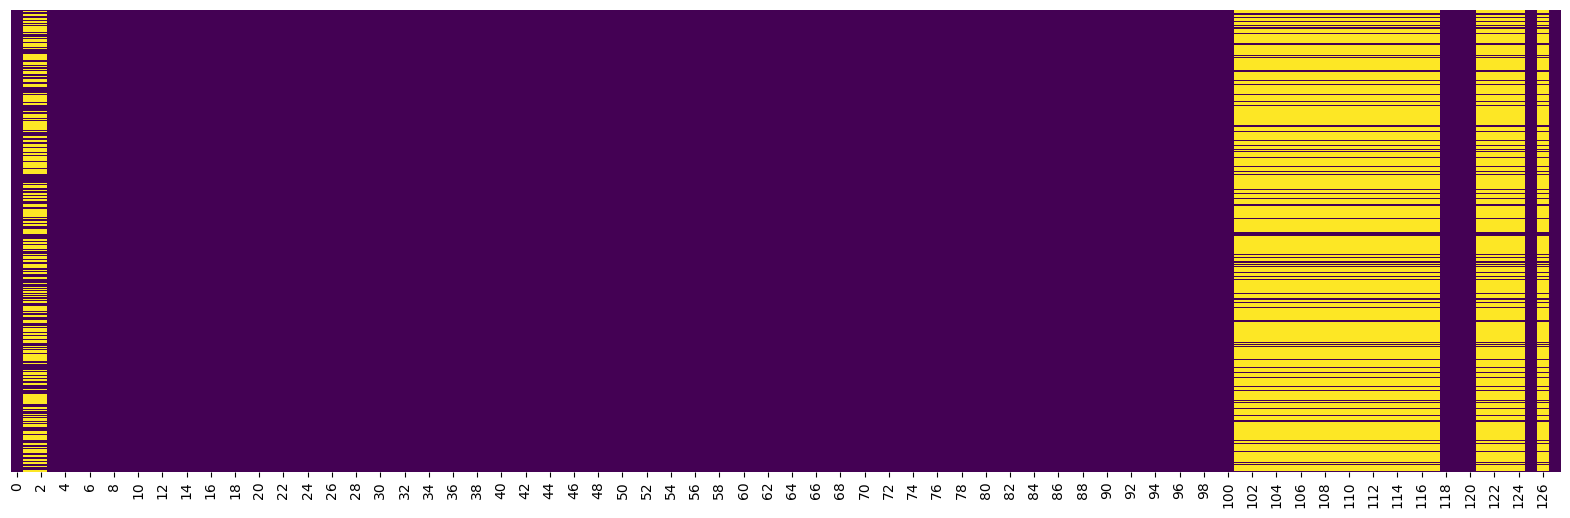

In [36]:
plt.figure(figsize=(20, 6))
sns.heatmap(crime.isnull(),yticklabels=False,cbar=False,cmap='viridis')

# Explicación: Visualizamos dónde existen datos faltantes en la base.

In [37]:
# Eliminar las características categóricas
crime.drop([0, 1, 2, 3, 4], axis=1, inplace=True)

# Quitamos cinco columnas que no se usarán en este análisis. 

In [38]:
# Eliminar las filas con algún valor faltante
crime.dropna(inplace=True)

#Conservamos únicamente las observaciones completas.

<Axes: >

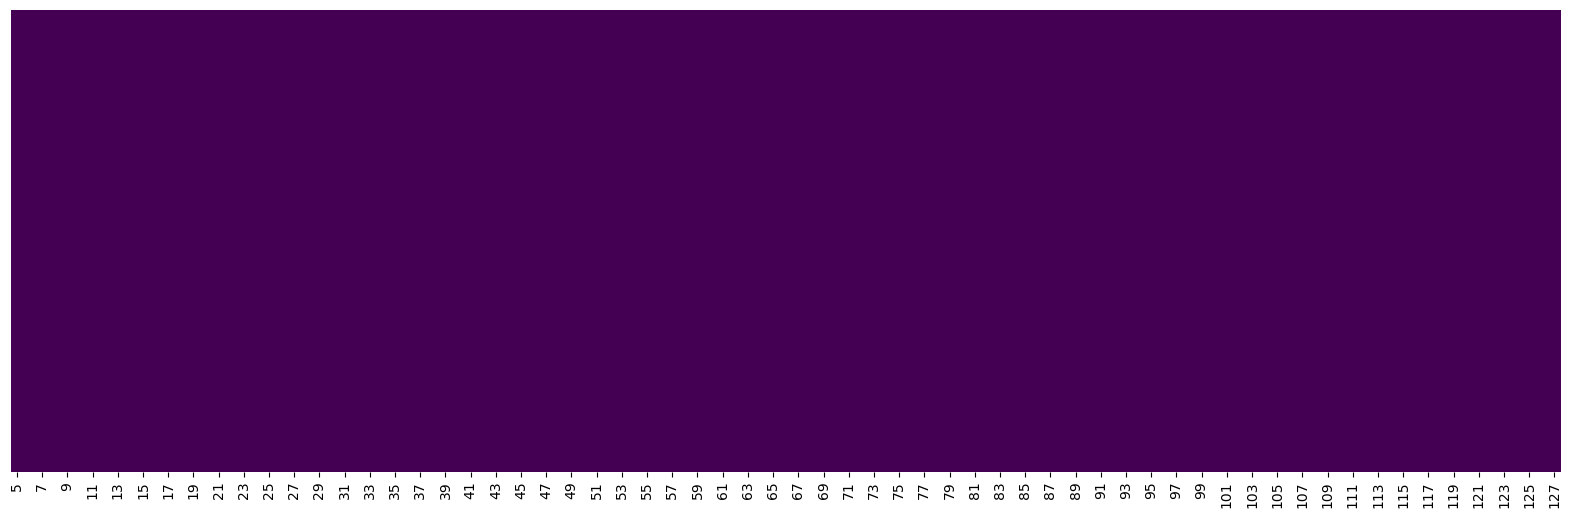

In [39]:
plt.figure(figsize=(20, 6))
sns.heatmap(crime.isnull(),yticklabels=False,cbar=False,cmap='viridis')

#Revisamos nuevamente que los valores faltantes hayan desaparecido.

In [40]:
# Verificar las dimensiones de la base
crime.shape

# Contamos las filas y columnas que quedaron después de limpiar la base.

(319, 123)

In [41]:
# Definir X e y
X = crime.drop(127, axis=1)
y = crime[127]

# Explicación: Separamos las variables explicativas (`X`) y la variable por predecir (`y`). 

In [42]:
# Dividir los datos en entrenamiento y prueba
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size = 0.3, random_state=1)

# Reservamos el 30 % de los datos para evaluar las predicciones y usamos el resto para entrenar.

### Regresión lineal. 

In [43]:
# Construir un modelo de regresión lineal
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train)

#Ajustamos un modelo sin regularización que servirá de comparación.

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [44]:
print ("INTERCEPT : ",linreg.intercept_)
print ("CO-EFFICIENT : ",linreg.coef_)

#Consultamos el intercepto y los coeficientes estimados.

INTERCEPT :  0.9922125287586239
CO-EFFICIENT :  [-3.93018330e+00  7.31324716e-01 -3.01181421e-01 -2.96634778e-01
 -1.83170801e-01  2.81575284e-01 -1.48744636e+00 -4.84695533e-01
  1.24104896e+00 -5.32282788e-01  4.64331123e+00 -1.17079618e-01
  1.04229108e+00  1.36950901e-01 -3.12434116e-01 -1.16489196e+00
  5.37252913e-01  7.49655606e-01 -8.02500871e-02  8.42449509e-01
 -1.98951720e-01 -3.17193999e-01 -4.31217869e-01  1.19357660e-01
 -1.83148129e-01  2.11602690e-01 -1.57441950e-01 -1.03051105e+00
  1.49628176e+00  1.86093900e-01 -1.12289917e+00 -1.13107576e-02
  1.22670519e-01  1.46348876e-01 -1.64172731e-01 -3.73690589e-02
  1.92733806e-01  4.34808503e-01  2.32870361e+00 -5.15176228e-01
  2.64683754e+00 -5.48075999e+00  9.63873430e-01 -1.15021921e+00
 -1.15575665e+00  1.10543276e+00  2.41469970e-01 -6.32209680e-01
  6.01741978e-01  8.37645340e-02  1.05006759e-01 -2.58807800e-01
  5.31513493e-01 -8.57090632e-01 -3.29684470e-01  6.61114510e-01
 -5.61884511e-01  6.27806334e-01  2.798480

In [45]:
# Realizar predicciones
y_pred = linreg.predict(X_test)

#Predecimos el resultado para las observaciones de prueba.

In [46]:
# Calcular R², MAE, MSE y RMSE

from sklearn.metrics import r2_score
from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

#Medimos qué tan bien predice nuestro modelo.# calculate R^2 value, MAE, MSE, RMSE


R-Square Value 0.19704456295410067
mean_absolute_error : 0.16725155824888152
mean_squared_error :  0.049863454226933446
root_mean_squared_error :  0.2233012633796178


MSE es más popular que MAE porque MSE “elimina” errores mayores. Pero RMSE es incluso mejor que MSE porque RMSE se puede interpretar en las unidades “y”.

## 1.4.3 Ridge regression
- Documentación de Ridge.
- alpha: debe ser positivo, aumentar para una mayor regularización.
- normalizar: escala las características (sin usar StandardScaler).

In [49]:
# Alfa igual a cero equivale a regresión lineal
from sklearn.linear_model import Ridge
ridgereg = Ridge(alpha=0)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

# Probamos Ridge sin penalización y comparamos sus errores.

R-Square Value 0.19704456295386097
mean_absolute_error : 0.16725155824891455
mean_squared_error :  0.04986345422694833
root_mean_squared_error :  0.22330126337965114


In [52]:
# Probar alfa igual a 0.1
ridgereg = Ridge(alpha=0.1)
ridgereg.fit(X_train, y_train)
y_pred = ridgereg.predict(X_test)

# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

#Aplicamos penalización a los coeficientes y volvemos a medir el error.

R-Square Value 0.5262899491498697
mean_absolute_error : 0.12670910679284872
mean_squared_error :  0.029417347897045934
root_mean_squared_error :  0.1715148620296385


In [53]:
# Examinar los coeficientes
print(ridgereg.coef_)

#Vemos cómo Ridge modificó los coeficientes al penalizarlos.

[ 0.05387341  0.08777086 -0.07857429 -0.06655408 -0.06702733  0.13302291
 -0.1370288  -0.09679891  0.04005784  0.10895944  0.14510316 -0.0607175
  0.24718976 -0.14383986 -0.16294646 -0.7013852  -0.08493163  0.25651168
 -0.0640989   0.31370894 -0.16763968 -0.01301493 -0.21263312 -0.03834742
 -0.04809351  0.18745164 -0.00624572 -0.45494164  0.42996759 -0.15264878
 -0.34532288  0.01863149  0.23713783  0.07415328 -0.19601847  0.05728627
  0.21630242  0.07246309  0.10444008  0.02840552 -0.24635709 -0.14606914
  0.21525031 -0.30256506 -0.28703885  0.14805249 -0.03272993 -0.21056436
  0.26965804 -0.03832653  0.25220687 -0.13023572  0.09021605 -0.33033235
  0.16968566  0.05538314 -0.07564988  0.01935623  0.15338743 -0.20692943
  0.12604865  0.16218614 -0.04463706 -0.15395487 -0.02984134  0.05967376
 -0.33486134  0.02951153  0.13938822  0.41776989  0.04696951  0.11288745
  0.13816489  0.17877385 -0.04233009  0.08900267 -0.01499668  0.04060738
 -0.1509511  -0.08987278 -0.08621681  0.03927102 -0.

In [54]:
# Crear un arreglo de valores alfa
alpha_range = 10.**np.arange(-2, 3)
alpha_range

#Preparamos distintos niveles de penalización para compararlos.

array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02])

In [56]:
# Seleccionar el mejor alfa con RidgeCV
from sklearn.linear_model import RidgeCV
ridgeregcv = RidgeCV(alphas=alpha_range, scoring='neg_mean_squared_error')

ridgeregcv.fit(X_train, y_train)
ridgeregcv.alpha_

# Evaluamos varios valores de alfa con validación cruzada y obtenemos el seleccionado.

10.0

In [57]:
# El método predict utiliza el mejor valor de alfa
y_pred = ridgeregcv.predict(X_test)
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

# Explicación: Evaluamos las predicciones del Ridge con el alfa seleccionado.

R-Square Value 0.5442422344114519
mean_absolute_error : 0.13277523657131673
mean_squared_error :  0.028302512735454543
root_mean_squared_error :  0.16823350657777583


### 1.4.4 Lasso regression
- Documentación de Lasso.
- alpha: debe ser positivo, aumentar para una mayor regularización.
- normalizar: escala las características (sin usar StandardScaler).

In [59]:
# Probar alfa igual a 0.001 y examinar los coeficientes
from sklearn.linear_model import Lasso
lassoreg = Lasso(alpha=0.001)
lassoreg.fit(X_train, y_train)
print(lassoreg.coef_)

# Ajustamos Lasso y observamos cuáles coeficientes quedan en cero.

[-0.         -0.          0.02952448 -0.1287308   0.          0.00397093
 -0.         -0.         -0.          0.         -0.          0.
 -0.         -0.03506582 -0.02065343 -0.19306594  0.          0.0087343
 -0.          0.          0.          0.         -0.         -0.05959218
  0.          0.01419686  0.         -0.08367502  0.         -0.
 -0.         -0.          0.1588383  -0.         -0.10618712  0.
  0.         -0.          0.06905018  0.          0.          0.
  0.         -0.13432462 -0.17544062 -0.         -0.         -0.
 -0.         -0.          0.14102046 -0.         -0.         -0.
 -0.         -0.          0.          0.          0.          0.
 -0.          0.          0.          0.         -0.          0.
 -0.          0.          0.          0.0895257  -0.          0.
 -0.          0.          0.          0.          0.          0.
 -0.         -0.         -0.         -0.         -0.09238764 -0.
 -0.         -0.         -0.         -0.         -0.06494622  0.032

In [61]:
# Probar alfa igual a 0.01 y examinar los coeficientes
lassoreg = Lasso(alpha=0.01)
lassoreg.fit(X_train, y_train)
print(lassoreg.coef_)

#Aumentamos la penalización y comprobamos si Lasso elimina más variables.

[ 0.         -0.          0.03599774 -0.23321176  0.          0.
  0.          0.          0.          0.          0.          0.
 -0.         -0.         -0.         -0.          0.          0.004772
 -0.         -0.         -0.         -0.         -0.         -0.
 -0.         -0.         -0.          0.          0.08100163  0.
  0.         -0.          0.         -0.         -0.          0.
  0.         -0.          0.          0.          0.          0.
  0.         -0.         -0.14312013 -0.07280454 -0.         -0.
 -0.          0.          0.19728557  0.          0.          0.
  0.          0.          0.          0.          0.          0.
 -0.          0.          0.          0.         -0.         -0.
  0.         -0.          0.          0.         -0.          0.01620678
 -0.         -0.          0.00075449  0.          0.          0.
  0.         -0.         -0.         -0.         -0.         -0.
 -0.         -0.          0.         -0.         -0.          0.
  0.1096124

In [62]:
# Calcular RMSE (para alfa igual a 0.01)
y_pred = lassoreg.predict(X_test)
# Calcular MAE, MSE y RMSE
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

# Explicación: Medimos el desempeño de Lasso con la penalización elegida.

R-Square Value 0.549435901066182
mean_absolute_error : 0.13629414371437606
mean_squared_error :  0.027979986543389814
root_mean_squared_error :  0.16727219297716467


In [64]:
# Seleccionar el mejor alfa con LassoCV
from sklearn.linear_model import LassoCV
lassoregcv = LassoCV(n_alphas=100,random_state=1)
lassoregcv.fit(X_train, y_train)
print('alpha : ',lassoregcv.alpha_)

# Buscamos automáticamente el nivel de penalización mediante validación cruzada.

alpha :  0.0029564957162874247


In [65]:
# Examinar los coeficientes
print(lassoregcv.coef_)

#Comprobamos cuáles variables conserva el Lasso seleccionado.

[ 0.         -0.          0.05482897 -0.21590313 -0.          0.
  0.         -0.          0.          0.          0.          0.
 -0.         -0.         -0.         -0.0398597   0.          0.03838033
 -0.         -0.         -0.         -0.         -0.         -0.
 -0.          0.         -0.          0.          0.13216579  0.
  0.         -0.          0.02523867 -0.         -0.          0.
  0.         -0.          0.11986949  0.          0.          0.
  0.         -0.02528178 -0.2950619  -0.         -0.         -0.
 -0.         -0.          0.08750744  0.         -0.         -0.
  0.          0.          0.          0.          0.          0.
 -0.          0.          0.          0.         -0.         -0.
 -0.         -0.          0.00949807  0.         -0.          0.
 -0.         -0.          0.          0.          0.          0.
  0.         -0.         -0.         -0.         -0.01256026 -0.
 -0.         -0.          0.         -0.         -0.          0.
  0.16720255  0. 

In [66]:
# El método predict utiliza el mejor valor de alfa
y_pred = lassoregcv.predict(X_test)
# Calcular R², MAE, MSE y RMSE

from sklearn import metrics
print("R-Square Value",r2_score(y_test,y_pred))
print ("mean_absolute_error :",metrics.mean_absolute_error(y_test, y_pred))
print ("mean_squared_error : ",metrics.mean_squared_error(y_test, y_pred))
print ("root_mean_squared_error : ",np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

#Evaluamos el desempeño final de LassoCV en los datos de prueba.

R-Square Value 0.5439920815003264
mean_absolute_error : 0.13445102835805997
mean_squared_error :  0.028318047206806436
root_mean_squared_error :  0.1682796696181878
